# 09 – Which layer tells how much? (baseline evaluation, part 1)

Baseline from now on: **6 indicators with POI and intersections counted within 300 m (07), k = 6**, all of MOL (27,465 cells).

We ask how much each of the 6 indicators (one per layer) contributes to the clusters, in three ways:

1. **Separation (eta²):** for each indicator, the share of its variance that lies *between* clusters. 1 = the clusters split this indicator perfectly, 0 = all clusters look the same on it.
   Simple, but it only describes the result – it does not tell us whether the clustering *needs* the indicator.
2. **Drop one indicator:** re-cluster without it (same pipeline, k = 6) and compare with the full clustering.
   - **ARI / NMI** (1 = identical). Low value = the indicator changes the clustering a lot = it carries information the others don't have.
   - **Which clusters fall apart:** for every full cluster, the largest share of its cells that stays together in one cluster of the reduced run.
3. **Stability over k:** how the k = 6 clusters relate to k = 5 and k = 7 (do clusters split/merge cleanly, or does everything reshuffle?).

Reference for "no change": the same full pipeline with a different random seed (only k-means randomness).

- **Input:** `cells.gpkg`, `ind_*.csv`, `clusters_radius.csv`
- **Output:** `data/processed/layer_contribution.csv`, figures `09_*.png`

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy.ndimage import convolve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

SEED = 0
K = 6
RADIUS = 300
CELL = 100
WATER_THRESHOLD = 0.5
DORM_CELL = "SIHM100_4603_1014"
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

FEATURES = ["pop", "imp_share", "bld_height", "can_cover", "poi_r300", "str_intersections_r300"]
LOG_FEATURES = ["pop", "poi_r300", "str_intersections_r300"]
LAYER = {"pop": "people", "imp_share": "imperviousness", "bld_height": "buildings", "can_cover": "greenery",
         "poi_r300": "function (POI)", "str_intersections_r300": "streets"}
# Tentative names of the 300 m, k = 6 clusters on MOL (07, re-run 1 Nov 2026)
NAMES = {0: "forest", 1: "open land", 2: "sparse residential / villages", 3: "urban residential",
         4: "non-residential", 5: "centre / mixed"}

## 2. Load and build the baseline features
Exactly as in 07: same cells, dorm cap, log, z-score. We check that we get the same clusters as saved in `clusters_radius.csv`.

In [2]:
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
data = cells.set_index("cell_id").drop(columns="geometry")
for name in ["buildings", "land_cover", "poi", "streets", "radius"]:
    data = data.join(pd.read_csv(PROCESSED / f"ind_{name}.csv", index_col="cell_id"))

use = data["bld_in_data"] & ~(data["ndvi_neg_share"] > WATER_THRESHOLD)
X = data.loc[use, FEATURES].copy()
X.loc[DORM_CELL, "pop"] = X["pop"].drop(DORM_CELL).max()
X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

def cluster(Zsub, seed=SEED):
    """k-means with 20 starts; labels renumbered by mean imperviousness (as in 06/07)."""
    lab = KMeans(n_clusters=K, n_init=20, random_state=seed).fit_predict(Zsub)
    order = Z.groupby(lab)["imp_share"].mean().sort_values().index
    return pd.Series(lab, index=Zsub.index).map({old: new for new, old in enumerate(order)})

full = cluster(Z)
saved = pd.read_csv(PROCESSED / "clusters_radius.csv", index_col="cell_id")["cluster"]
print(f"{len(Z):,} cells; same as clusters_radius.csv: {(full == saved.loc[full.index]).all()}")
print(full.map(NAMES).value_counts().to_string())

C:\Users\Maks\miniforge3\envs\urban\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


27,465 cells; same as clusters_radius.csv: True
forest                           11331
open land                         8395
sparse residential / villages     3103
urban residential                 2670
non-residential                   1376
centre / mixed                     590


## 3. Separation: eta² per indicator
eta² = between-cluster variance / total variance of the (transformed, standardised) indicator.

In [3]:
def eta2(col, lab):
    total = ((col - col.mean()) ** 2).sum()
    within = ((col - col.groupby(lab).transform("mean")) ** 2).sum()
    return 1 - within / total

sep = pd.Series({f: eta2(Z[f], full) for f in FEATURES}, name="eta2").sort_values(ascending=False)
sep.to_frame().assign(layer=sep.index.map(LAYER)).round(3)

,eta2,layer
can_cover,0.872,greenery
imp_share,0.844,imperviousness
pop,0.835,people
poi_r300,0.710,function (POI)
bld_height,0.706,buildings
str_intersections_r300,0.673,streets


## 4. Drop one indicator at a time
For each indicator: cluster the other five (they keep their z-scores from the full set), k = 6, same seed. Compare with the full clustering.

**Reference:** the full set with 5 other seeds. Any difference smaller than this is just k-means randomness.

**Two ARIs:** forest and open land are 72 % of all cells, and ARI is dominated by large clusters. A layer that only separates forest from fields would look very important.
So we also compute ARI on the **built-up cells only** (full clusters 2–5: residential, non-residential, centre), which is where the urban types are.

In [4]:
ref = [cluster(Z, seed=s) for s in range(1, 6)]
ref_ari = np.mean([adjusted_rand_score(full, r) for r in ref])
ref_nmi = np.mean([normalized_mutual_info_score(full, r) for r in ref])
built = full >= 2
ref_ari_built = np.mean([adjusted_rand_score(full[built], r[built]) for r in ref])
print(f"Reference (full set, other seeds): ARI {ref_ari:.3f}, NMI {ref_nmi:.3f}, ARI built-up {ref_ari_built:.3f}")

dropped = {f: cluster(Z.drop(columns=f)) for f in FEATURES}

def kept_together(full_lab, other_lab):
    """For each full cluster: largest share of its cells that ends up in one cluster of the other run."""
    return pd.crosstab(full_lab, other_lab, normalize="index").max(axis=1)

rows = []
for f, lab in dropped.items():
    kt = kept_together(full, lab)
    rows.append({"dropped": f, "layer": LAYER[f],
                 "ARI vs full": adjusted_rand_score(full, lab),
                 "NMI vs full": normalized_mutual_info_score(full, lab),
                 "ARI built-up": adjusted_rand_score(full[built], lab[built]),
                 "cells changing cluster": 1 - (pd.crosstab(full, lab).max(axis=1).sum() / len(full)),
                 **{NAMES[c]: kt[c] for c in range(K)}})
drop = pd.DataFrame(rows).set_index("dropped").sort_values("ARI vs full")
drop.round(2)

Reference (full set, other seeds): ARI 0.994, NMI 0.986, ARI built-up 0.983


,layer,ARI vs full,NMI vs full,ARI built-up,cells changing cluster,forest,open land,sparse residential / villages,urban residential,non-residential,centre / mixed
dropped,,,,,,,,,,,
can_cover,greenery,0.45,0.58,0.47,0.19,0.96,0.77,0.51,0.60,0.93,0.62
pop,people,0.85,0.77,0.51,0.12,0.99,0.83,0.90,0.72,0.70,0.63
bld_height,buildings,0.89,0.82,0.49,0.09,1.00,0.99,0.58,0.72,0.97,0.62
imp_share,imperviousness,0.91,0.83,0.48,0.08,0.99,0.96,0.72,0.73,0.85,0.85
poi_r300,function (POI),0.93,0.86,0.70,0.06,0.99,0.94,0.86,0.95,0.90,0.52
str_intersections_r300,streets,0.93,0.87,0.71,0.04,0.99,0.99,0.78,0.91,0.96,0.95


**Reading the table:** the columns named after clusters show how much of each full cluster stays together when the indicator is missing.
A value well below 1 means that cluster *depends* on this indicator – without it, the cluster dissolves into others.
Careful: if two full clusters **merge**, both still look "kept together". The cross-tables below show merges and splits.

In [5]:
for f in drop.index:
    print(f"Without {LAYER[f]}: rows = full clusters, columns = clusters of the reduced run (sizes {dropped[f].value_counts().sort_index().tolist()})")
    display(pd.crosstab(full.map(lambda c: f"{c}: {NAMES[c]}").rename("full"), dropped[f].rename(f"without {f}"), normalize="index").round(2))

Without greenery: rows = full clusters, columns = clusters of the reduced run (sizes [17365, 4039, 2555, 1822, 1319, 365])


without can_cover,0,1,2,3,4,5
full,,,,,,
0: forest,0.96,0.04,0.00,0.00,0.00,0.00
1: open land,0.77,0.23,0.00,0.00,0.00,0.00
2: sparse residential / villages,0.00,0.51,0.49,0.00,0.00,0.00
3: urban residential,0.00,0.00,0.39,0.60,0.01,0.00
4: non-residential,0.00,0.06,0.01,0.00,0.93,0.00
5: centre / mixed,0.00,0.00,0.00,0.35,0.03,0.62


Without people: rows = full clusters, columns = clusters of the reduced run (sizes [11206, 7082, 4343, 3181, 1437, 216])


without pop,0,1,2,3,4,5
full,,,,,,
0: forest,0.99,0.01,0.01,0.00,0.00,0.00
1: open land,0.00,0.83,0.17,0.00,0.00,0.00
2: sparse residential / villages,0.01,0.01,0.90,0.09,0.00,0.00
3: urban residential,0.00,0.00,0.02,0.72,0.26,0.00
4: non-residential,0.00,0.00,0.03,0.70,0.27,0.00
5: centre / mixed,0.00,0.00,0.00,0.00,0.63,0.37


Without buildings: rows = full clusters, columns = clusters of the reduced run (sizes [11510, 9294, 2541, 2131, 1615, 374])


without bld_height,0,1,2,3,4,5
full,,,,,,
0: forest,1.00,0.00,0.00,0.00,0.00,0.00
1: open land,0.01,0.99,0.00,0.00,0.01,0.00
2: sparse residential / villages,0.04,0.32,0.58,0.00,0.05,0.00
3: urban residential,0.00,0.00,0.27,0.72,0.01,0.00
4: non-residential,0.00,0.01,0.00,0.01,0.97,0.01
5: centre / mixed,0.00,0.00,0.00,0.33,0.05,0.62


... (2 outputs left out)

Without function (POI): rows = full clusters, columns = clusters of the reduced run (sizes [11262, 7933, 3343, 3108, 429, 1390])


without poi_r300,0,1,2,3,4,5
full,,,,,,
0: forest,0.99,0.00,0.00,0.00,0.00,0.00
1: open land,0.00,0.94,0.06,0.00,0.00,0.00
2: sparse residential / villages,0.00,0.00,0.86,0.13,0.00,0.01
3: urban residential,0.00,0.00,0.01,0.95,0.04,0.00
4: non-residential,0.00,0.00,0.08,0.00,0.01,0.90
5: centre / mixed,0.00,0.00,0.01,0.27,0.52,0.20


Without streets: rows = full clusters, columns = clusters of the reduced run (sizes [11321, 8790, 2672, 2645, 1446, 591])


without str_intersections_r300,0,1,2,3,4,5
full,,,,,,
0: forest,0.99,0.01,0.00,0.00,0.00,0.00
1: open land,0.01,0.99,0.00,0.00,0.00,0.00
2: sparse residential / villages,0.01,0.13,0.78,0.06,0.02,0.00
3: urban residential,0.00,0.00,0.07,0.91,0.01,0.01
4: non-residential,0.00,0.02,0.01,0.01,0.96,0.01
5: centre / mixed,0.00,0.00,0.00,0.02,0.03,0.95


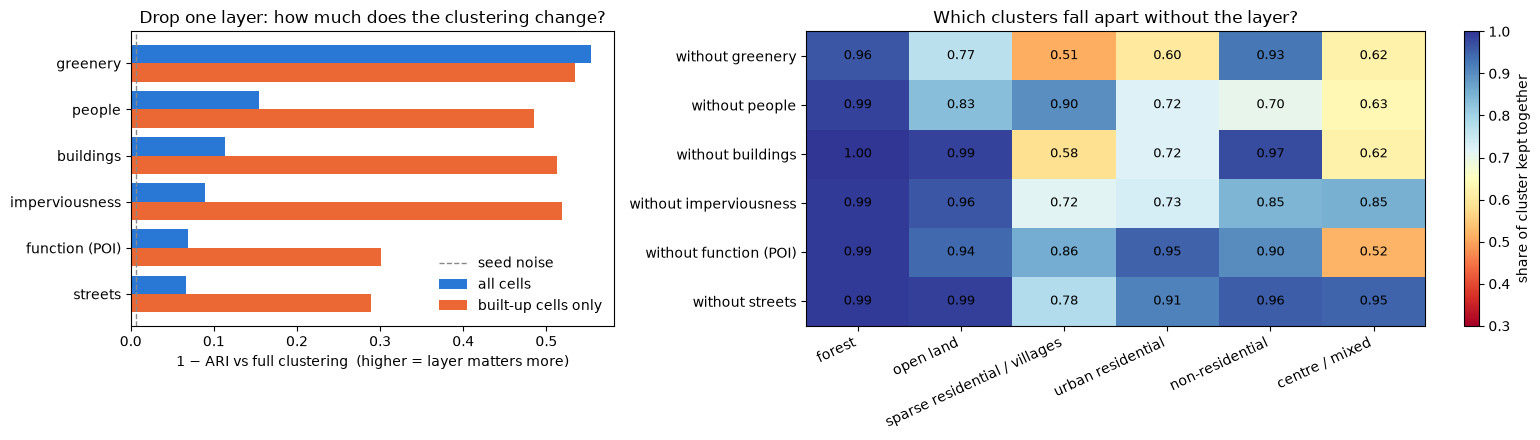

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

ax = axes[0]
order = drop.index
y = np.arange(len(order))
ax.barh(y - 0.2, 1 - drop["ARI vs full"], height=0.4, color="#2a78d6", label="all cells")
ax.barh(y + 0.2, 1 - drop["ARI built-up"], height=0.4, color="#eb6834", label="built-up cells only")
ax.set_yticks(y, [LAYER[f] for f in order])
ax.axvline(1 - ref_ari, color="#888888", linestyle="--", linewidth=1, label="seed noise")
ax.set_xlabel("1 − ARI vs full clustering  (higher = layer matters more)")
ax.invert_yaxis()
ax.legend(frameon=False)
ax.set_title("Drop one layer: how much does the clustering change?")

ax = axes[1]
kt = drop[[NAMES[c] for c in range(K)]]
im = ax.imshow(kt, cmap="RdYlBu", vmin=0.3, vmax=1, aspect="auto")
ax.set_xticks(range(K), kt.columns, rotation=25, ha="right")
ax.set_yticks(range(len(kt)), [f"without {LAYER[f]}" for f in kt.index])
for i in range(kt.shape[0]):
    for j in range(K):
        ax.text(j, i, f"{kt.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="share of cluster kept together")
ax.set_title("Which clusters fall apart without the layer?")
plt.tight_layout()
fig.savefig(FIGURES / "09_drop_one_layer.png", dpi=150, bbox_inches="tight")
plt.show()

### Maps: full clustering vs the two most influential drops
Same colours = same cluster number (numbered by imperviousness), so colours are roughly comparable.

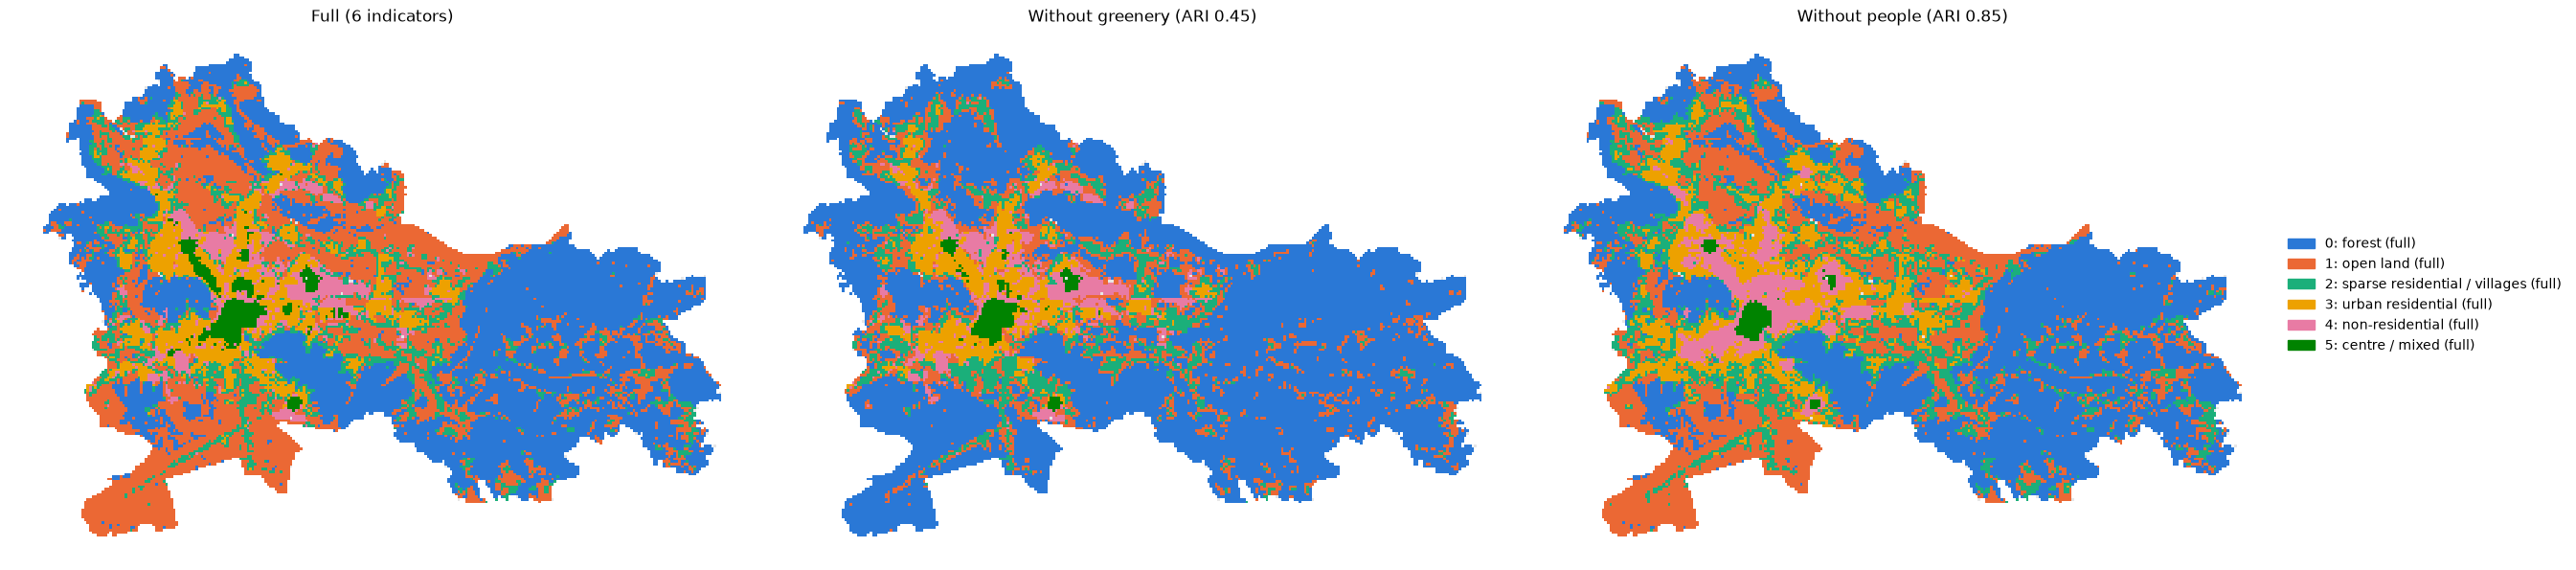

In [7]:
cmap = ListedColormap(CLUSTER_COLORS[:K])
show = [("Full (6 indicators)", full)] + [(f"Without {LAYER[f]} (ARI {drop.loc[f, 'ARI vs full']:.2f})", dropped[f]) for f in drop.index[:2]]
fig, axes = plt.subplots(1, 3, figsize=(27, 9))
for ax, (title, lab) in zip(axes, show):
    g_ = cells[["cell_id", "geometry"]].merge(lab.rename("cluster").reset_index(), on="cell_id", how="left")
    g_[g_["cluster"].isna()].plot(ax=ax, color="#e6e6e6", linewidth=0)
    g_.dropna(subset=["cluster"]).plot(ax=ax, column="cluster", cmap=cmap, vmin=-0.5, vmax=K - 0.5, linewidth=0)
    ax.set_title(title)
    ax.set_axis_off()
handles = [Patch(color=CLUSTER_COLORS[c], label=f"{c}: {NAMES[c]} (full)") for c in range(K)]
axes[2].legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "09_maps_drop_one.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Stability over k
Do the k = 6 clusters relate cleanly to k = 5 and k = 7? Ideally going from 6 to 5 merges two clusters and leaves the rest alone, and going to 7 splits one.
Rows = k = 6 clusters, values = share of the row.

In [8]:
for k in (5, 7):
    other = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z)
    ct = pd.crosstab(full.map(lambda c: f"{c}: {NAMES[c]}").rename("k = 6"), pd.Series(other, index=Z.index, name=f"k = {k}"), normalize="index")
    print(f"k = 6 vs k = {k}: ARI {adjusted_rand_score(full, other):.3f}")
    display(ct.round(2))

k = 6 vs k = 5: ARI 0.857


k = 5,0,1,2,3,4
k = 6,,,,,
0: forest,1.00,0.00,0.00,0.00,0.00
1: open land,0.01,0.00,0.00,0.00,0.98
2: sparse residential / villages,0.02,0.46,0.00,0.06,0.45
3: urban residential,0.00,0.90,0.09,0.00,0.00
4: non-residential,0.00,0.01,0.02,0.97,0.00
5: centre / mixed,0.00,0.00,1.00,0.00,0.00


k = 6 vs k = 7: ARI 0.864


k = 7,0,1,2,3,4,5,6
k = 6,,,,,,,
0: forest,0.99,0.00,0.01,0.00,0.00,0.01,0.00
1: open land,0.00,0.00,0.85,0.00,0.00,0.15,0.00
2: sparse residential / villages,0.00,0.00,0.00,0.33,0.00,0.67,0.00
3: urban residential,0.00,0.01,0.00,0.55,0.44,0.00,0.00
4: non-residential,0.00,0.91,0.00,0.01,0.01,0.08,0.00
5: centre / mixed,0.00,0.03,0.00,0.00,0.42,0.00,0.54


## 6. Save

In [9]:
out = drop.join(sep).reset_index()
out.insert(0, "reference_seed_ari", ref_ari)
out.to_csv(PROCESSED / "layer_contribution.csv", index=False)
print("Saved layer_contribution.csv")

Saved layer_contribution.csv


## Summary (first run, 1 Nov 2026)

Baseline: 300 m radius features, k = 6, 27,465 cells. Seed noise is tiny (ARI 0.994 all cells, 0.983 built-up), so every effect below is real.

| dropped layer | ARI all cells | ARI built-up | what happens without it |
|---|---|---|---|
| greenery (`can_cover`) | **0.45** | 0.47 | forest and open land merge (77 % of open land joins forest); the freed cluster re-splits residential |
| people (`pop`) | 0.85 | 0.49 | non-residential merges with urban residential (70 %); the centre splits |
| buildings (`bld_height`) | 0.89 | 0.49 | a third of sparse residential/villages joins open land; a third of the centre joins urban residential |
| imperviousness (`imp_share`) | 0.91 | 0.48 | moderate reshuffle of all built-up clusters; no cluster disappears |
| function (`poi_r300`) | 0.93 | 0.70 | **the centre dissolves** (only 52 % stays together): it splits into a high-rise cluster and urban residential |
| streets (`str_intersections_r300`) | 0.93 | 0.71 | smallest change; mostly the edge between sparse and urban residential moves |

**What we take from this:**
- On all cells, greenery looks by far the most important, but that is mostly because forest vs open land (72 % of cells) depends only on it. That split is about land cover, not urban types.
- **Inside the built-up area, the four form layers matter about equally** (ARI about 0.5 without any one of them): people, buildings, imperviousness and greenery each carry information the others don't. None is redundant.
- **Imperviousness** separates clusters strongly (eta² 0.84), but on all cells dropping it changes the clustering the least of the form layers: much of what it says is also said by height, people and canopy. Inside the built-up area it still matters.
- **POI** has a smaller overall effect (0.70), but it is the only layer that **defines the centre**: small in cells, large in meaning.
- **Streets** add the least that the other layers don't already contain. First candidate to drop if we want fewer indicators, but it does not hurt.

**Stability over k:** k = 6 → 5 does not simply merge two clusters: sparse residential/villages is split between urban residential and open land (ARI 0.86).
k = 6 → 7 splits urban residential and the centre (ARI 0.86). The sparse residential cluster is the least stable one: it is the transition zone between town and countryside.

**Next (phase 3, part 2):** spatial coherence: Moran's I / join counts and fragmentation of the clusters.